# Module 8 — Prognostic Gene Signature

**Biological question:** Can a small set of genes, selected purely from bulk RNA-seq, predict a breast cancer patient's overall survival? And does this gene-level signature add prognostic information beyond knowing the PAM50 subtype?

**Method:**
1. **Gene selection:** Screen all DE-significant genes with univariate Cox regression. Rank by p-value; keep the top 50. This filters for genes whose expression is associated with survival, not just genes that differ between subtypes.
2. **Signature fitting:** Fit a regularised (L2 penalised) Cox model on the selected genes. The regularisation penalizer=0.1 shrinks coefficients and prevents overfitting to the training data.
3. **Risk score:** For each patient, compute log partial hazard = `X_genes · β`. Higher score = higher predicted hazard = worse prognosis.
4. **Validation:** Split patients at the median risk score; compare KM curves for high-risk vs low-risk groups.
5. **Comparison:** How does the C-index of the gene signature model compare to a PAM50-only Cox model?

**C-index (concordance index):** Fraction of all patient pairs where the model correctly ranks which patient dies first. C = 0.5 is chance; C = 1.0 is perfect ordering.

In [1]:
import sys
sys.path.insert(0, "..")

import logging
import pickle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import KaplanMeierFitter
from lifelines.plotting import add_at_risk_counts

from src.constants import DataFile, InterimFile
from src.paths import interim_file, raw_file, PROCESSED_DIR
from src.models.survival import merge_survival, fit_cox
from src.models.survival_prediction import (
    select_prognostic_genes,
    fit_cox_signature,
    compute_risk_score,
)

logging.basicConfig(level=logging.INFO, format="%(message)s")

## Load Data

In [2]:
X_log = pd.read_csv(interim_file(InterimFile.X), index_col=0)

labels = pd.read_csv(interim_file(InterimFile.LABELS), index_col=0).squeeze()

surv_raw = pd.read_csv(raw_file(DataFile.SURVIVAL), sep="\t", index_col=0)
survival_df = merge_survival(labels=labels, raw_survival_df=surv_raw)

de = pd.read_csv(interim_file(InterimFile.DE_RESULTS))

print(f"X_log: {X_log.shape}")
print(f"Survival: {len(survival_df)} patients")
print(f"DE: {len(de):,} rows")

merge_survival: 825 samples joined, 825 kept after dropping missing OS.time


X_log: (842, 6000)
Survival: 825 patients
DE: 30,000 rows


## Select Top 50 Prognostic Genes (Univariate Cox Screening)

For each DE-significant gene, fit a Cox model with just that gene's log-expression as the predictor. Keep the top 50 ranked by p-value. This takes a few minutes.

In [3]:
genes = select_prognostic_genes(
    de_results=de,
    survival_df=survival_df,
    X_log=X_log,
    fdr_threshold=0.05,
    n_genes=50,
)
print(f"Selected {len(genes)} prognostic genes")
print(genes[:10])

Screening 5818 DE genes for univariate Cox significance ...


Selected 50 prognostic genes (top by univariate Cox p-value)


Selected 50 prognostic genes
['ENSG00000260573.4', 'ENSG00000120471.15', 'ENSG00000170835.16', 'ENSG00000142319.18', 'ENSG00000279965.1', 'ENSG00000161133.16', 'ENSG00000164434.12', 'ENSG00000009709.12', 'ENSG00000211898.7', 'ENSG00000184486.10']


## Fit Regularised Cox Signature Model

In [4]:
cph_sig = fit_cox_signature(
    X_log=X_log,
    survival_df=survival_df,
    gene_ids=genes,
    penalizer=0.1,
)
print(f"Signature C-index: {cph_sig.concordance_index_:.3f}")

Cox signature: 50 genes, C-index = 0.793


Signature C-index: 0.793


## Compute Risk Scores and Median Split

In [5]:
risk_scores = compute_risk_score(X_log=X_log, cox_fitter=cph_sig, gene_ids=genes)

shared = risk_scores.index.intersection(survival_df.index)
df_risk = survival_df.loc[shared].copy()
df_risk["risk_score"] = risk_scores.loc[shared]
df_risk["risk_group"] = pd.cut(
    df_risk["risk_score"],
    bins=[
        df_risk["risk_score"].min() - 0.001,
        df_risk["risk_score"].median(),
        df_risk["risk_score"].max(),
    ],
    labels=["Low risk", "High risk"],
)
print(df_risk["risk_group"].value_counts())

Risk scores: 842 samples, range [-2.058, 2.675]


risk_group
Low risk     413
High risk    412
Name: count, dtype: int64


## KM Curves: High vs Low Risk

A well-calibrated prognostic signature should produce clearly separated survival curves. The log-rank p-value quantifies whether the separation is statistically significant.

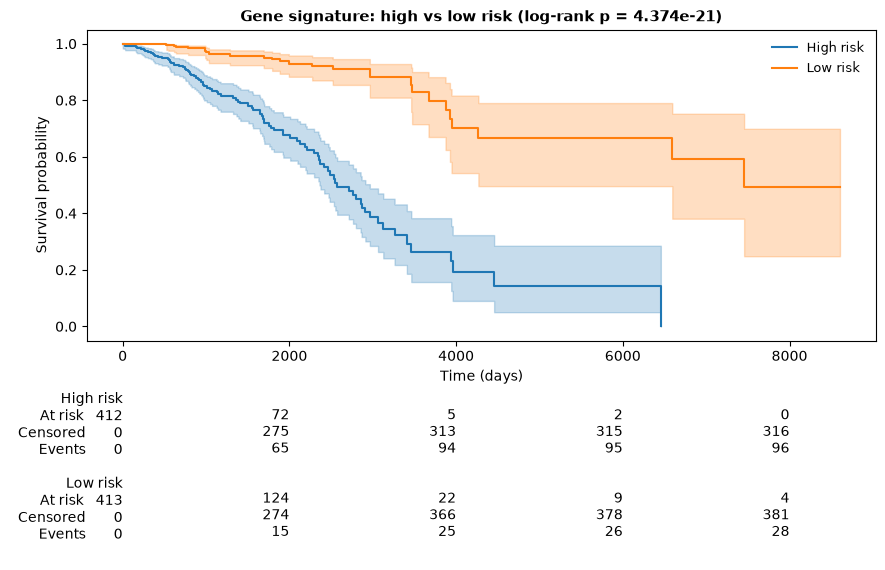

In [6]:
from lifelines.statistics import logrank_test

high = df_risk.loc[df_risk["risk_group"] == "High risk"]
low = df_risk.loc[df_risk["risk_group"] == "Low risk"]

lr = logrank_test(
    durations_A=high["OS_time"],
    durations_B=low["OS_time"],
    event_observed_A=high["OS_event"],
    event_observed_B=low["OS_event"],
)

fig, ax = plt.subplots(figsize=(9, 6))
fitters = []
for group, sub in [("High risk", high), ("Low risk", low)]:
    kmf = KaplanMeierFitter(label=group)
    kmf.fit(durations=sub["OS_time"], event_observed=sub["OS_event"])
    kmf.plot_survival_function(ax=ax, ci_show=True)
    fitters.append(kmf)

add_at_risk_counts(*fitters, ax=ax)
ax.set_title(
    f"Gene signature: high vs low risk (log-rank p = {lr.p_value:.3e})",
    fontsize=11, fontweight="bold",
)
ax.set_xlabel("Time (days)")
ax.set_ylabel("Survival probability")
ax.legend(fontsize=9, frameon=False)
plt.tight_layout()
plt.show()

## Which Genes Drive the Signature?

Positive Cox coefficient → higher expression = higher hazard (bad prognosis). Negative → higher expression = lower hazard (protective). Recognised genes like MKI67 (proliferation), ESR1 (oestrogen receptor), and ERBB2 (HER2) validate the biological plausibility.

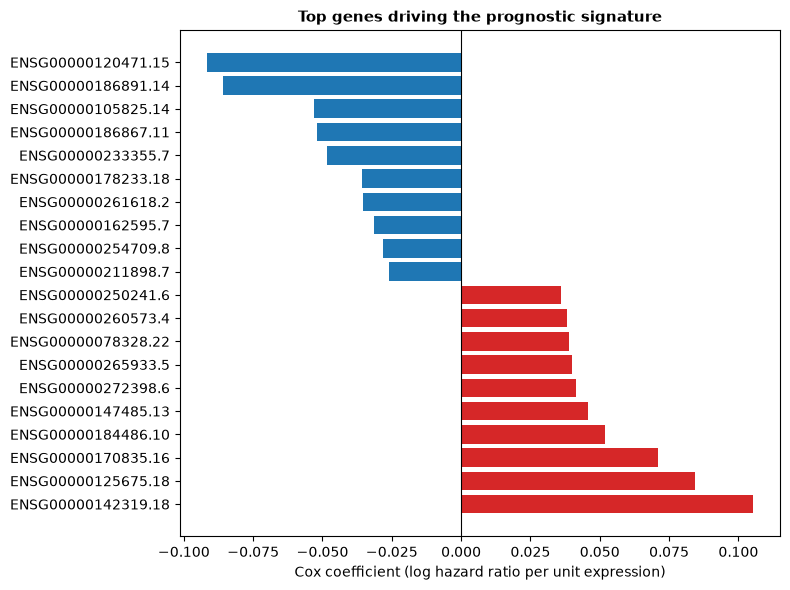

In [7]:
sig_coefs = cph_sig.params_.loc[genes].sort_values(ascending=False)
top_n = 20
top_coefs = pd.concat([sig_coefs.head(top_n // 2), sig_coefs.tail(top_n // 2)])

fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#d62728" if c > 0 else "#1f77b4" for c in top_coefs]
ax.barh(top_coefs.index, top_coefs.values, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Cox coefficient (log hazard ratio per unit expression)")
ax.set_title("Top genes driving the prognostic signature", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

## Comparison: Gene Signature vs PAM50-Only Cox Model

Does the gene signature provide value beyond the PAM50 subtype label that a clinician already has? We compare C-indices of two models:
- **PAM50-only:** Cox with subtype as the sole covariate.
- **Gene signature:** Cox on the 50 selected genes.

In [8]:
cph_pam50 = fit_cox(df=survival_df, covariates=["subtype"])

print(f"PAM50-only Cox C-index:      {cph_pam50.concordance_index_:.3f}")
print(f"Gene signature Cox C-index:  {cph_sig.concordance_index_:.3f}")

Cox model fitted; concordance index = 0.548


PAM50-only Cox C-index:      0.548
Gene signature Cox C-index:  0.793


## Save Model Outputs

In [9]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

out_model = PROCESSED_DIR / "cox_signature.pkl"
with open(out_model, "wb") as f:
    pickle.dump({"cph": cph_sig, "genes": genes}, f)
print(f"Saved {out_model.name}")

out_scores = PROCESSED_DIR / "risk_scores.csv"
risk_scores.to_csv(out_scores, header=True)
print(f"Saved {out_scores.name}")

genes_series = pd.Series(genes, name="gene")
out_genes = interim_file(InterimFile.PROGNOSTIC_GENES)
genes_series.to_csv(out_genes, index=False)
print(f"Saved {out_genes.name}")

Saved cox_signature.pkl


Saved risk_scores.csv


Saved prognostic_genes.csv.gz
